first is the setup

In [1]:
import spacy
import pandas as pd
from textblob import TextBlob

nlp = spacy.load("en_core_web_sm")

then let create some sample text 

In [2]:
posts = [
    "The camera is not good but the battery is great.",
    "I love the amazing screen on this phone.",
    "The service was terrible and the staff was rude.",
    "What a fast delivery and a helpful driver!",
]

look for dependancy parse 

In [3]:
doc = nlp(posts[0])
for token in doc:
    print(f"{token.text:<10} {token.pos_:<6} {token.dep_:<8} head={token.head.text}")

The        DET    det      head=camera
camera     NOUN   nsubj    head=is
is         AUX    ROOT     head=is
not        PART   neg      head=is
good       ADJ    acomp    head=is
but        CCONJ  cc       head=is
the        DET    det      head=battery
battery    NOUN   nsubj    head=is
is         AUX    conj     head=is
great      ADJ    acomp    head=is
.          PUNCT  punct    head=is


camera is the nsubj (subject) of is
good is the acomp (adjective complement) of is
not is a neg (negation) attached to is

These links are what we use to connect each noun to its opinion word.

Extract keywords and phrases with dependency rules

Two simple patterns:

Adjective modifier (amod): “amazing screen” → noun screen, opinion amazing
Subject + adjective complement (nsubj + acomp): “battery is great” → noun battery, opinion great

If the verb has a neg child (“is not good”), we mark the opinion as negated.

In [4]:
def extract_aspect_opinions(doc):
    pairs = []
    for token in doc:
        # Pattern 1: adjective directly modifying a noun
        if token.dep_ == "amod" and token.head.pos_ in ("NOUN", "PROPN"):
            negated = any(c.dep_ == "neg" for c in token.children)
            pairs.append((token.head.text, token.text, negated))

        # Pattern 2: "noun is adjective"
        if token.dep_ == "acomp":
            verb = token.head
            negated = any(c.dep_ == "neg" for c in verb.children)
            for child in verb.children:
                if child.dep_ == "nsubj":
                    pairs.append((child.text, token.text, negated))
    return pairs

# Test on one post
extract_aspect_opinions(nlp(posts[0]))

[('camera', 'good', True), ('battery', 'great', False)]

Analyze sentiment of each aspect

In [5]:
def label(score):
    if score > 0:
        return "Positive"
    elif score < 0:
        return "Negative"
    return "Neutral"

rows = []
for post in posts:
    doc = nlp(post)
    for aspect, opinion, negated in extract_aspect_opinions(doc):
        score = TextBlob(opinion).sentiment.polarity
        if negated:
            score = -score
        rows.append({
            "Post": post,
            "Aspect (keyword)": aspect,
            "Opinion": ("not " if negated else "") + opinion,
            "Polarity": round(score, 2),
            "Sentiment": label(score),
        })

df = pd.DataFrame(rows)
df

,Post,Aspect (keyword),Opinion,Polarity,Sentiment
0,The camera is not good but the battery is great.,camera,not good,-0.7,Negative
1,The camera is not good but the battery is great.,battery,great,0.8,Positive
2,I love the amazing screen on this phone.,screen,amazing,0.6,Positive
3,The service was terrible and the staff was rude.,service,terrible,-1.0,Negative
4,The service was terrible and the staff was rude.,staff,rude,-0.3,Negative
5,What a fast delivery and a helpful driver!,delivery,fast,0.2,Positive
6,What a fast delivery and a helpful driver!,driver,helpful,0.0,Neutral


Keyword phrases (noun chunks) as an extra view

In [6]:
for post in posts:
    doc = nlp(post)
    print(post)
    print("  Phrases:", [chunk.text for chunk in doc.noun_chunks])

The camera is not good but the battery is great.
  Phrases: ['The camera', 'the battery']
I love the amazing screen on this phone.
  Phrases: ['I', 'the amazing screen', 'this phone']
The service was terrible and the staff was rude.
  Phrases: ['The service', 'the staff']
What a fast delivery and a helpful driver!
  Phrases: ['What a fast delivery', 'a helpful driver']


In [7]:
summary = df.groupby("Aspect (keyword)")["Polarity"].mean().round(2).sort_values()
summary

Aspect (keyword)
service    -1.0
camera     -0.7
staff      -0.3
driver      0.0
delivery    0.2
screen      0.6
battery     0.8
Name: Polarity, dtype: float64

In [8]:
overall = df["Polarity"].mean()
print(f"Overall score: {overall:.2f} -> {label(overall)}")
print()
print(df["Sentiment"].value_counts())

Overall score: -0.06 -> Negative

Sentiment
Negative    3
Positive    3
Neutral     1
Name: count, dtype: int64


<Axes: title={'center': 'Average sentiment per aspect'}, ylabel='Aspect (keyword)'>

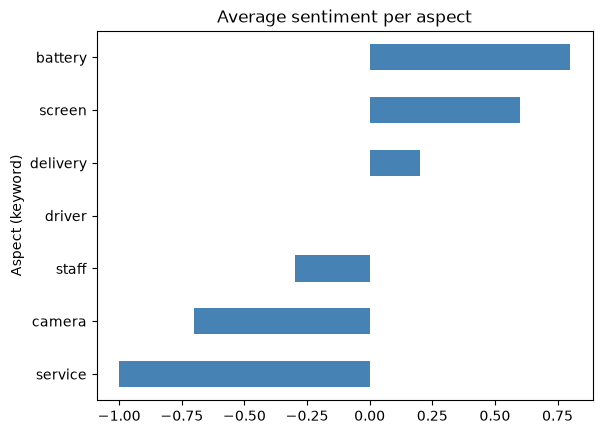

In [9]:
summary.plot(kind="barh", color="steelblue", title="Average sentiment per aspect")